# Trabajo Final: Introducción a la Inteligencia Artificial

**Diplomatura en Inteligencia Artificial**  
Universidad Nacional de Luján (UNLu)

**Autor:** Victor Manuel Bravo Arroyo  
**Curso:** Introducción a la Inteligencia Artificial


## Índice de Contenidos

- [1. Introducción y Definición del Problema](#1.-Introducción-y-Definición-del-Problema)
- [2. Configuración del Entorno y Carga de Datos](#2.-Configuración-del-Entorno-y-Carga-de-Datos)
- [3. Análisis Exploratorio de Datos (EDA)](#3.-Análisis-Exploratorio-de-Datos-(EDA))
- [4. Preprocesamiento e Ingeniería de Características](#4.-Preprocesamiento-e-Ingeniería-de-Características)
  - [4.1. Renombre de Variables](#4.1.-Renombre-de-Variables)
  - [4.2. Análisis y Depuración de Valores Faltantes](#4.2.-Análisis-y-Depuración-de-Valores-Faltantes)
  - [4.3. Codificación de Variables Binarias y Categóricas (One-Hot Encoding)](#4.3.-Codificación-de-Variables-Binarias-y-Categóricas-(One-Hot-Encoding))
  - [4.4. Deflactación por Inflación con IPC y Variable Objetivo](#4.4.-Deflactación-por-Inflación-con-IPC-y-Variable-Objetivo)
  - [4.5. Ingeniería de Características y Codificación One-Hot](#4.5.-Ingeniería-de-Características-y-Codificación-One-Hot)
  - [4.6. Análisis de Correlación de Pearson](#4.6.-Análisis-de-Correlación-de-Pearson)
- [5. Modelado y Entrenamiento](#5.-Modelado-y-Entrenamiento)
  - [5.1. Selección de Variables por Umbral de Correlación](#5.1.-Selección-de-Variables-por-Umbral-de-Correlación)
  - [5.2. Ajuste de Hiperparámetros en Random Forest (Grid Search)](#5.2.-Ajuste-de-Hiperparámetros-en-Random-Forest-(Grid-Search))
  - [5.3. Partición Temporal y Entrenamiento Final](#5.3.-Partición-Temporal-y-Entrenamiento-Final)
- [6. Evaluación de Resultados](#6.-Evaluación-de-Resultados)
  - [6.1. Comparación de Métricas en Test (2024)](#6.1.-Comparación-de-Métricas-en-Test-(2024))
  - [6.2. Diagnóstico del Desempeño en Test (2024) y Efecto Macroeconómico](#6.2.-Diagnóstico-del-Desempeño-en-Test-(2024)-y-Efecto-Macroeconómico)
  - [6.3. Interpretabilidad: Coeficientes Estandarizados vs. Importancia en Random Forest](#6.3.-Interpretabilidad:-Coeficientes-Estandarizados-vs.-Importancia-en-Random-Forest)
- [7. Conclusiones y Consideraciones Éticas](#7.-Conclusiones-y-Consideraciones-Éticas)


## 1. Introducción y Definición del Problema

Este trabajo predice el gasto turístico real diario por persona en Argentina usando microdatos de la Encuesta de Viajes y Turismo de los Hogares (EVyTH, relevamiento oficial del Ministerio de Turismo) y el índice de precios al consumidor (IPC del INDEC) del período 2012–2024. Para comparar valores entre años, los montos se deflactan con IPC a precios de 2016 y se transforman a logaritmo. Se limpian los datos, se seleccionan variables por correlación y se comparan dos modelos con partición temporal (entrenamiento 2012–2023 vs. test 2024): Regresión Lineal y Random Forest.

Ambos modelos empatan en desempeño sobre el conjunto de test (MAE ≈ 0.88, RMSE ≈ 1.14), por lo que la complejidad del Random Forest no mejora la predicción frente a la regresión lineal ante la caída de ingresos reales de 2024. Los predictores con mayor impacto en el gasto son el tipo de alojamiento (vivienda propia o familiares vs. hotel), el transporte en avión y el tamaño del grupo de viaje.


## 2. Configuración del Entorno y Carga de Datos


In [1]:
# Instalación de dependencias (para entornos tipo Google Colab o Jupyter sin dependencias previas)
!pip install -q numpy==2.1.3 pandas==2.2.3 scikit-learn==1.7.2 matplotlib==3.10.8 seaborn==0.13.2 scipy==1.15.1



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

In [3]:
os.makedirs("data", exist_ok=True)

urls = {
    "data/evyth_microdatos.csv": "https://datos.yvera.gob.ar/dataset/b5819e9b-5edf-4aad-bd39-a81158a2b3f3/resource/645e5505-68ee-4cfa-90f9-fcc9a4a34a85/download/evyth_microdatos.csv",
    "data/evyth_diccionario_registro.csv": "https://datos.yvera.gob.ar/dataset/b5819e9b-5edf-4aad-bd39-a81158a2b3f3/resource/d8107236-f5ba-428d-8a31-f9b2034d8c8f/download/evyth_diccionario_registro.csv",
    "data/ipc_mensual_indec.csv": "https://apis.datos.gob.ar/series/api/series?ids=145.3_INGNACNAL_DICI_M_15&format=csv&limit=1000",
}

for path, url in urls.items():
    if not os.path.exists(path):
        print(f"Descargando {path}...")
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as response, open(path, "wb") as f_out:
            f_out.write(response.read())
        print(f"Descargado: {path}")
    else:
        print(f"Ya existe: {path}")

df_encuesta = pd.read_csv("data/evyth_microdatos.csv")
df_dicc = pd.read_csv("data/evyth_diccionario_registro.csv")
df_ipc = pd.read_csv("data/ipc_mensual_indec.csv")

print("Encuesta shape:", df_encuesta.shape)
print("Diccionario shape:", df_dicc.shape)
print("IPC shape:", df_ipc.shape)

Ya existe: data/evyth_microdatos.csv
Ya existe: data/evyth_diccionario_registro.csv
Ya existe: data/ipc_mensual_indec.csv
Encuesta shape: (490904, 88)
Diccionario shape: (480, 3)
IPC shape: (117, 29)


## 3. Análisis Exploratorio de Datos (EDA)

El archivo `evyth_microdatos.csv` codifica las preguntas del cuestionario con prefijos como `px*` y `p0*` y guarda las respuestas como números enteros. El archivo `evyth_diccionario_registro.csv` define qué significa cada columna y cada código numérico (por ejemplo, `px09` corresponde al medio de transporte, donde `1 = Automóvil`, `2 = Ómnibus`, `4 = Avión`). Cruzamos ambos para renombrar las columnas y traducir los códigos a texto legible.

```text
+-------------------------------------------------+
|      evyth_diccionario_registro.csv             |
|      (Metadatos de la encuesta)                 |
|      - variable: nombre técnico (px09, etc.)    |
|      - opcion: código numérico (1, 2, 4)        |
|      - descripcion: etiqueta legible            |
+-------------------------------------------------+
                       |
                       | Mapea columnas técnicas y decodifica valores
                       v
+-------------------------------------------------+
|      evyth_microdatos.csv (Tabla Principal)    |
|      (490.904 viajes registrados 2012-2024)     |
|      - anio, trimestre                          |
|      - transporte, alojamiento, noches          |
|      - gasto_pc: monto nominal en pesos         |
+-------------------------------------------------+
                       ^
                       | Cruce por [anio, trimestre] para deflactar gasto_pc
                       |
+-------------------------------------------------+
|      ipc_mensual_indec.csv                      |
|      (Serie de Precios INDEC, base dic-2016)    |
|      - indice_tiempo: fecha mes a mes           |
|      - ipc_nivel_general_nacional: índice base  |
+-------------------------------------------------+
```


In [4]:
# EVyTH: Microdatos de la Encuesta de Viajes y Turismo de los Hogares (viajes, destinos, gastos y perfiles)
df_encuesta.head()

,id_hogar,id_viajes,miembro,anio,trimestre,region_origen,aglomerado_origen,region_destino,provincia_destino,localidad_destino,cod_loc_2001,codigo_2001,codigo_2010,cod_prov_2010,cod_depto_2010,cod_loc_2010,pondera,tipo_visitante,cantidad_destinos,multidestino,px06,px06_agrup,px07,px07_agrup,px08,px08_agrup,px09,px10_1,px11,px12_1,px12_2,px12_3,px12_4,px12_5,px12_6,px12_7,px12_8,px13,px14,px15_1,px15_2,px15_3,px15_4,pxb16_1_1,pxb16_1_2,pxb16_1_3,pxb16_1_4,pxb16_1_5,pxb16_1_6,pxb16_1_7,pxb16_1_9,pxb16_2,px17_1,px17_2_1,px17_2_2,px17_2_3,px17_2_4,px17_2_5,px17_2_6,px17_2_7,px17_2_8,px17_2_9,px17_2_10,px17_2_11,px17_2_12,px17_2_13,px18_1,px18_2,px18_3,px18_4,px18_5,px18_6,px18_7,gasto_pc,quintil_pcf_visitante,p002,p004,p005,p006,p006_agrup,p007,nivel_ed,cond_act,p013,j_sexo,j_edad,j_nivel_ed,j_cond_act
0,71,41201,1,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,1,1,54,4,2.0,7,1,2,1,3,4,1
1,71,41201,2,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,2,2,56,4,2.0,4,1,3,1,3,4,1
2,71,41201,3,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1
3,71,41201,4,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,1,27,2,2.0,9,1,3,1,3,4,1
4,71,61201,3,2012,1,2,33,3,6,Reta ...,819,6833070.0,6833070.0,6.0,833.0,70.0,1175.0,1,1,1,1,1,10,3.0,4,2,1,1,2.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,3.0,1.0,9.0,9.0,9.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,6.0,100.0,10.0,9.0,10.0,10.0,8.0,700.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1


In [5]:
# Diccionario EVyTH: Mapeo de variables y codigos categoricos a sus etiquetas descriptivas
df_dicc.head(n=10)

,variable,opcion,descripcion
0,id_hogar,NaN,Código de identificación único de hogares
1,id_viajes,NaN,Código de identificación único de viajes
2,miembro,NaN,Número de miembro en el hogar
3,anio,NaN,Año
4,trimestre,NaN,Trimestre
5,region_origen,NaN,Región de residencia del hogar
6,region_origen,1.0,Ciudad de Buenos Aires
7,region_origen,2.0,Provincia de Buenos Aires - Partidos del GBA
8,region_origen,3.0,Provincia de Buenos Aires - Resto
9,region_origen,4.0,Centro


In [6]:
# Ejemplo con px09 (medio de transporte): valores en crudo vs. join con el diccionario
dicc_px09 = df_dicc[df_dicc["variable"] == "px09"]
print("--- Definición de px09 en el diccionario ---")
display(dicc_px09)

ejemplo_px09 = (
    df_encuesta[["px09"]]
    .value_counts()
    .reset_index(name="cantidad_viajes")
    .merge(dicc_px09[["opcion", "descripcion"]], left_on="px09", right_on="opcion")[
        ["px09", "descripcion", "cantidad_viajes"]
    ]
)
print("--- Cruce (join) de códigos de px09 con sus etiquetas ---")
display(ejemplo_px09)

--- Definición de px09 en el diccionario ---


,variable,opcion,descripcion
130,px09,NaN,¿Qué medio de transporte utilizaron para ir ha...
131,px09,1.0,Automóvil o similar (propio)
132,px09,2.0,Omnibus
133,px09,3.0,Tren
134,px09,4.0,Avión
135,px09,5.0,Embarcación
136,px09,6.0,Taxi o remís
137,px09,8.0,"Otro (auto alquilado, motocicleta, bicicleta, ..."
138,px09,99.0,Ns./ Nr.


--- Cruce (join) de códigos de px09 con sus etiquetas ---


,px09,descripcion,cantidad_viajes
0,1,Automóvil o similar (propio),402712
1,2,Omnibus,65403
2,4,Avión,15341
3,8,"Otro (auto alquilado, motocicleta, bicicleta, ...",3008
4,3,Tren,2855
5,5,Embarcación,799
6,6,Taxi o remís,579
7,99,Ns./ Nr.,207


In [7]:
# IPC: Indice de Precios al Consumidor mensual INDEC (apertura por categorias, base dic-2016)
df_ipc.head()

,indice_tiempo,ipc_nivel_general_nacional,ipc_estacionales_nacional,ipc_nucleo_nacional,ipc_regulados_nacional,ipc_nivel_general_gba,ipc_estacionales_gba,ipc_nucleo_gba,ipc_regulados_gba,ipc_nivel_general_pampeana,ipc_estacionales_pampeana,ipc_nucleo_pampeana,ipc_regulados_pampeana,ipc_nivel_general_nea,ipc_estacionales_nea,ipc_nucleo_nea,ipc_regulados_nea,ipc_nivel_general_noa,ipc_estacionales_noa,ipc_nucleo_noa,ipc_regulados_noa,ipc_nivel_general_cuyo,ipc_estacionales_cuyo,ipc_nucleo_cuyo,ipc_regulados_cuyo,ipc_nivel_general_patagonia,ipc_estacionales_patagonia,ipc_nucleo_patagonia,ipc_regulados_patagonia
0,2016-12-01,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
1,2017-01-01,101.5859,101.6969,101.5039,101.8183,101.3130,101.5562,101.3389,101.1274,101.7874,102.0904,101.6093,102.2331,101.6727,102.4771,101.8639,100.3476,101.6014,101.5611,101.4339,102.2777,101.7074,100.6608,101.7235,102.2456,102.5593,100.6843,101.8374,106.1556
2,2017-02-01,103.6859,102.3345,103.2105,105.9316,103.8085,102.0783,103.2097,106.3489,103.5312,102.6254,103.1957,105.2868,103.4617,104.0713,103.4466,103.0912,103.7115,103.5611,102.9705,106.6823,103.2652,100.3694,103.1488,105.2775,104.2827,101.1740,103.5240,108.7652
3,2017-03-01,106.1476,104.7868,105.2057,110.0057,106.2627,105.8790,105.0891,109.8871,105.8173,104.1769,105.3123,108.6317,105.9880,104.9091,105.4076,109.0469,107.0550,104.2786,105.2640,115.9572,105.9238,102.0721,105.2127,110.4082,106.5167,102.5219,105.2611,113.2246
4,2017-04-01,108.9667,108.1867,107.4270,114.4649,109.0613,108.5334,107.4973,113.8991,108.6912,108.5973,107.3262,113.6053,108.3473,107.1165,107.5916,112.2076,109.9626,107.7699,107.4536,121.2229,109.4506,106.6856,107.6553,116.8444,108.6517,105.1970,107.0217,116.2906


## 4. Preprocesamiento e Ingeniería de Características

### 4.1. Renombre de Variables
Se mapean las 88 variables del microdato original a nombres descriptivos en español según el diccionario oficial.

In [8]:
renombrar_columnas = {
    # 1. Identificadores y ponderador
    "id_hogar": "id_hogar",
    "id_viajes": "id_viaje",
    "miembro": "id_miembro",
    "pondera": "ponderador",
    # 2. Fechas y Geografía
    "anio": "anio",
    "trimestre": "trimestre",
    "region_origen": "region_origen",
    "aglomerado_origen": "aglomerado_origen",
    "region_destino": "region_destino",
    "provincia_destino": "provincia_destino",
    "localidad_destino": "localidad_destino",
    "cod_loc_2001": "cod_localidad_2001",
    "codigo_2001": "cod_geo_2001",
    "codigo_2010": "cod_geo_2010",
    "cod_prov_2010": "cod_provincia_2010",
    "cod_depto_2010": "cod_departamento_2010",
    "cod_loc_2010": "cod_localidad_2010",
    # 3. Características del Viaje
    "tipo_visitante": "tipo_visitante",
    "cantidad_destinos": "cantidad_destinos",
    "multidestino": "es_multidestino",
    "px06": "miembros_viajaron",
    "px06_agrup": "miembros_viajaron_agrup",
    "px07": "noches_estadia",
    "px07_agrup": "noches_estadia_agrup",
    "px08": "alojamiento_detallado",
    "px08_agrup": "alojamiento",
    "px09": "transporte",
    "px10_1": "motivo_viaje",
    "px11": "contrato_paquete",
    # 4. Servicios incluidos en paquete turístico (px12_*)
    "px12_1": "paquete_transporte",
    "px12_2": "paquete_alojamiento",
    "px12_3": "paquete_algunas_comidas",
    "px12_4": "paquete_todas_comidas",
    "px12_5": "paquete_traslados_alquiler_auto",
    "px12_6": "paquete_excursiones_espectaculos",
    "px12_7": "paquete_seguro_asistencia",
    "px12_8": "paquete_otros_servicios",
    # 5. Planificación y reservas por internet (px13, px14, px15_*)
    "px13": "anticipacion_viaje",
    "px14": "uso_internet",
    "px15_1": "reserva_internet_paquete",
    "px15_2": "reserva_internet_alojamiento",
    "px15_3": "reserva_internet_transporte",
    "px15_4": "reserva_internet_excursiones",
    # 6. Razones de elección del destino y visitas previas (pxb16_*)
    "pxb16_1_1": "razon_atractivos_naturales",
    "pxb16_1_2": "razon_atractivos_culturales",
    "pxb16_1_3": "razon_cercania_acceso",
    "pxb16_1_4": "razon_precios",
    "pxb16_1_5": "razon_recomendacion_conocidos",
    "pxb16_1_6": "razon_residen_familiares_amigos",
    "pxb16_1_7": "razon_publicidad_medios",
    "pxb16_1_9": "evaluo_otro_destino",
    "pxb16_2": "visita_previa_destino",
    # 7. Actividades Turísticas (px17_1, px17_2_*)
    "px17_1": "hizo_actividades",
    "px17_2_1": "actividad_espacios_rurales",
    "px17_2_2": "actividad_spa_termas",
    "px17_2_3": "actividad_playa",
    "px17_2_4": "actividad_nieve_esqui",
    "px17_2_5": "actividad_aventura",
    "px17_2_6": "actividad_caza_pesca",
    "px17_2_7": "actividad_espectaculo_deportivo",
    "px17_2_8": "actividad_acto_religioso",
    "px17_2_9": "actividad_teatro_cine_conciertos",
    "px17_2_10": "actividad_museos_parques_tematicos",
    "px17_2_11": "actividad_parques_nacionales",
    "px17_2_12": "actividad_casinos_bingos",
    "px17_2_13": "actividad_vida_nocturna",
    # 8. Calificación de aspectos del viaje 1 a 10 (px18_*)
    "px18_1": "calif_transporte",
    "px18_2": "calif_alojamiento",
    "px18_3": "calif_gastronomia",
    "px18_4": "calif_informacion_turistica",
    "px18_5": "calif_higiene",
    "px18_6": "calif_seguridad",
    "px18_7": "calif_viaje_general",
    # 9. Gasto e Ingresos
    "gasto_pc": "gasto_pc",
    "quintil_pcf_visitante": "quintil_ingreso",
    # 10. Demografía del Viajero y del Jefe de Hogar
    "p002": "miembros_hogar",
    "p004": "parentesco_jefe",
    "p005": "sexo_viajero",
    "p006": "edad_viajero",
    "p006_agrup": "edad_viajero_agrup",
    "p007": "asiste_educacion",
    "nivel_ed": "nivel_educativo",
    "cond_act": "condicion_actividad",
    "p013": "cobertura_salud",
    "j_sexo": "sexo_jefe",
    "j_edad": "edad_jefe",
    "j_nivel_ed": "nivel_educativo_jefe",
    "j_cond_act": "condicion_actividad_jefe",
}

df_encuesta = df_encuesta.rename(columns=renombrar_columnas)
print("Total de columnas renombradas:", len(renombrar_columnas))
df_encuesta.head()

Total de columnas renombradas: 88


,id_hogar,id_viaje,id_miembro,anio,trimestre,region_origen,aglomerado_origen,region_destino,provincia_destino,localidad_destino,cod_localidad_2001,cod_geo_2001,cod_geo_2010,cod_provincia_2010,cod_departamento_2010,cod_localidad_2010,ponderador,tipo_visitante,cantidad_destinos,es_multidestino,miembros_viajaron,miembros_viajaron_agrup,noches_estadia,noches_estadia_agrup,alojamiento_detallado,alojamiento,transporte,motivo_viaje,contrato_paquete,paquete_transporte,paquete_alojamiento,paquete_algunas_comidas,paquete_todas_comidas,paquete_traslados_alquiler_auto,paquete_excursiones_espectaculos,paquete_seguro_asistencia,paquete_otros_servicios,anticipacion_viaje,uso_internet,reserva_internet_paquete,reserva_internet_alojamiento,reserva_internet_transporte,reserva_internet_excursiones,razon_atractivos_naturales,razon_atractivos_culturales,razon_cercania_acceso,razon_precios,razon_recomendacion_conocidos,razon_residen_familiares_amigos,razon_publicidad_medios,evaluo_otro_destino,visita_previa_destino,hizo_actividades,actividad_espacios_rurales,actividad_spa_termas,actividad_playa,actividad_nieve_esqui,actividad_aventura,actividad_caza_pesca,actividad_espectaculo_deportivo,actividad_acto_religioso,actividad_teatro_cine_conciertos,actividad_museos_parques_tematicos,actividad_parques_nacionales,actividad_casinos_bingos,actividad_vida_nocturna,calif_transporte,calif_alojamiento,calif_gastronomia,calif_informacion_turistica,calif_higiene,calif_seguridad,calif_viaje_general,gasto_pc,quintil_ingreso,miembros_hogar,parentesco_jefe,sexo_viajero,edad_viajero,edad_viajero_agrup,asiste_educacion,nivel_educativo,condicion_actividad,cobertura_salud,sexo_jefe,edad_jefe,nivel_educativo_jefe,condicion_actividad_jefe
0,71,41201,1,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,1,1,54,4,2.0,7,1,2,1,3,4,1
1,71,41201,2,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,2,2,56,4,2.0,4,1,3,1,3,4,1
2,71,41201,3,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1
3,71,41201,4,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,1,27,2,2.0,9,1,3,1,3,4,1
4,71,61201,3,2012,1,2,33,3,6,Reta ...,819,6833070.0,6833070.0,6.0,833.0,70.0,1175.0,1,1,1,1,1,10,3.0,4,2,1,1,2.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,3.0,1.0,9.0,9.0,9.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,6.0,100.0,10.0,9.0,10.0,10.0,8.0,700.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1


### 4.2. Análisis y Depuración de Valores Faltantes
Se calcula el porcentaje de valores nulos por columna para identificar variables no utilizables o módulos condicionales.

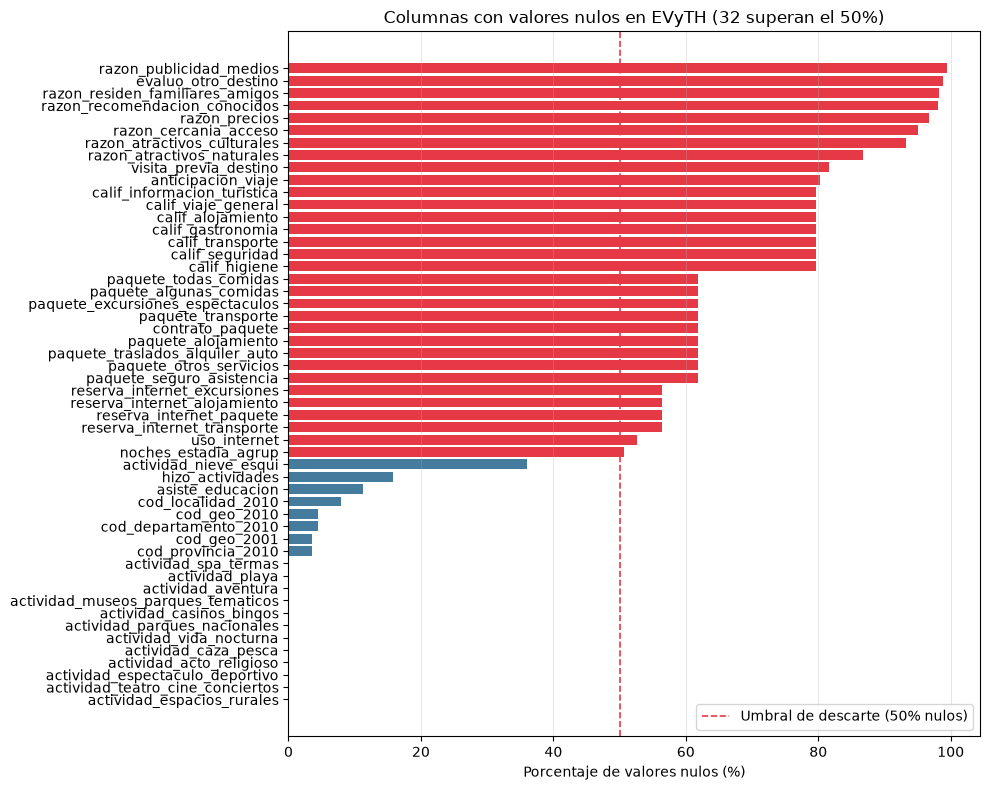

In [9]:
# Porcentaje de valores nulos por columna (gráfico de barras de columnas con datos faltantes)
porcentaje_nulos = (df_encuesta.isna().mean() * 100).round(2)
nulos_con_faltantes = porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=True)
nulos_criticos = porcentaje_nulos[porcentaje_nulos > 50].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
colores = ["#e63946" if v > 50 else "#457b9d" for v in nulos_con_faltantes.values]
ax.barh(nulos_con_faltantes.index, nulos_con_faltantes.values, color=colores)
ax.axvline(
    50,
    color="#e63946",
    linestyle="--",
    linewidth=1.2,
    label="Umbral de descarte (50% nulos)",
)
ax.set_xlabel("Porcentaje de valores nulos (%)")
ax.set_title(
    f"Columnas con valores nulos en EVyTH ({len(nulos_criticos)} superan el 50%)"
)
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

> **Valores nulos:** Las variables con más del 50% de nulos corresponden a preguntas condicionales (paquetes turísticos o reservas online) que la mayoría de los turistas no utiliza, por lo que se descartan para el modelado.


In [10]:
# Eliminación de columnas con más de 50% de nulos, identificadores y códigos geográficos
cols_descartar = [
    # Identificadores y ponderador muestral
    "id_hogar",
    "id_viaje",
    "id_miembro",
    "ponderador",
    # Códigos geográficos y redundancias territoriales (se conservan region_origen y region_destino)
    "localidad_destino",
    "provincia_destino",
    "aglomerado_origen",
    "cod_geo_2001",
    "cod_localidad_2001",
    "cod_geo_2010",
    "cod_provincia_2010",
    "cod_departamento_2010",
    "cod_localidad_2010",
    "cod_loc_2001",
    "codigo_2001",
    "codigo_2010",
    "cod_prov_2010",
    "cod_depto_2010",
    "cod_loc_2010",
    # Agrupaciones redundantes (se conservan las numéricas continuas)
    "miembros_viajaron_agrup",
    "noches_estadia_agrup",
    "edad_viajero_agrup",
    "alojamiento_detallado",
    # Atributos no predictivos del gasto turístico
    "parentesco_jefe",
    "asiste_educacion",
    "cobertura_salud",
] + nulos_criticos.index.tolist()

df_encuesta = df_encuesta.drop(columns=cols_descartar, errors="ignore")
print("Columnas restantes:", df_encuesta.shape[1])

Columnas restantes: 37


### 4.3. Codificación de Variables Binarias y Categóricas (One-Hot Encoding)
- **Variables binarias:** Las preguntas dicotómicas (actividades turísticas realizadas, sexo, tipo de visitante) se transforman a valores numéricos  y .
- **Variables categóricas nominales:** Se mapean los códigos numéricos de la encuesta (motivo de viaje, tipo de transporte, alojamiento, regiones de origen y destino) a etiquetas textuales descriptivas y se aplica *One-Hot Encoding* ( con ) para evitar colinealidad en modelos lineales.

In [11]:
# Variables binarias (Preguntas de Sí/No, sexo y actividades turísticas realizadas)
cols_binarias = [
    "tipo_visitante",
    "es_multidestino",
    "sexo_viajero",
    "sexo_jefe",
    "hizo_actividades",
    "actividad_espacios_rurales",
    "actividad_spa_termas",
    "actividad_playa",
    "actividad_nieve_esqui",
    "actividad_aventura",
    "actividad_caza_pesca",
    "actividad_espectaculo_deportivo",
    "actividad_acto_religioso",
    "actividad_teatro_cine_conciertos",
    "actividad_museos_parques_tematicos",
    "actividad_parques_nacionales",
    "actividad_casinos_bingos",
    "actividad_vida_nocturna",
]

# Conservar solo las presentes en el dataset tras la depuración
cols_binarias = [col for col in cols_binarias if col in df_encuesta.columns]

# Mapeo: 1 -> 1 (Sí/Opción afirmativa), todo lo demás (2: No, 9: Ns/Nr, NaN) -> 0
for col in cols_binarias:
    df_encuesta[col] = (df_encuesta[col] == 1).astype(int)

# Corrección de valores especiales en variable ordinal nivel_educativo (98: Educación especial, 99: Ns/Nr)
mediana_ed = df_encuesta.loc[
    df_encuesta["nivel_educativo"] <= 10, "nivel_educativo"
].median()
df_encuesta["nivel_educativo"] = df_encuesta["nivel_educativo"].replace(
    {98: mediana_ed, 99: mediana_ed}
)

print(f"Variables binarias transformadas a 0/1: {len(cols_binarias)}")

Variables binarias transformadas a 0/1: 18


In [12]:
# Mapeo de códigos numéricos a categorías textuales según diccionario de registro
mapeos_categoricos = {
    "alojamiento": {
        1: "vivienda_propia",
        2: "casa_familiares_amigos",
        3: "alquiler_temporario",
        4: "camping",
        5: "hotel_hasta_3_estrellas",
        6: "hotel_4_o_5_estrellas",
        7: "otro",
    },
    "transporte": {
        1: "auto_propio",
        2: "omnibus",
        3: "tren",
        4: "avion",
        5: "embarcacion",
        6: "taxi_remis",
        8: "otro",
        99: "ns_nr",
    },
    "motivo_viaje": {
        1: "ocio_vacaciones",
        2: "visita_familiares",
        3: "trabajo_negocios",
        4: "estudios",
        5: "salud",
        6: "religion",
        7: "compras",
        8: "otro",
        99: "ns_nr",
    },
    "region_origen": {
        1: "caba",
        2: "gba",
        3: "resto_pba",
        4: "centro",
        5: "litoral",
        6: "norte",
        7: "cuyo",
        8: "patagonia",
    },
    "region_destino": {
        1: "caba",
        2: "gba",
        3: "resto_pba",
        4: "centro",
        5: "litoral",
        6: "norte",
        7: "cuyo",
        8: "patagonia",
    },
    "condicion_actividad": {
        1: "ocupado",
        2: "desocupado",
        3: "inactivo",
        4: "menor_14",
        9: "ns_nr",
    },
    "condicion_actividad_jefe": {
        1: "ocupado",
        2: "desocupado",
        3: "inactivo",
        4: "menor_14",
        9: "ns_nr",
    },
}

for col, mapeo in mapeos_categoricos.items():
    df_encuesta[col] = df_encuesta[col].map(mapeo)

print("Variables categóricas mapeadas con éxito.")

Variables categóricas mapeadas con éxito.


### 4.4. Deflactación por Inflación con IPC y Variable Objetivo

Para comparar el gasto frente a la inflación en Argentina, se deflacta con el IPC trimestral (base dic-2016 = 100):

$$\text{gasto\_real} = \frac{\text{gasto\_pc}}{\text{ipc}} \times 100$$

$$\text{gasto\_diario\_real} = \frac{\text{gasto\_real}}{\text{noches\_estadia}}$$

$$\text{log\_gasto\_diario} = \ln(1 + \text{gasto\_diario\_real})$$

Se conservan observaciones válidas (`noches_estadia > 0`, `gasto_pc > 0`). La escala logarítmica normaliza la distribución y estabiliza la varianza.


In [13]:
# 1. Preparar IPC a nivel trimestral (promedio de los 3 meses de cada trimestre)
df_ipc["indice_tiempo"] = pd.to_datetime(df_ipc["indice_tiempo"])
df_ipc["anio"] = df_ipc["indice_tiempo"].dt.year
df_ipc["trimestre"] = df_ipc["indice_tiempo"].dt.quarter

ipc_trimestral = (
    df_ipc.groupby(["anio", "trimestre"])["ipc_nivel_general_nacional"]
    .mean()
    .reset_index()
)

# 2. Cruce: conserva únicamente viajes del período con serie oficial de IPC nacional continua (2016 en adelante)
df_encuesta = df_encuesta.merge(ipc_trimestral, on=["anio", "trimestre"], how="inner")

# 3. Filtrar población objetivo: turistas con estadía válida (al menos 1 noche) y gasto positivo
df_encuesta = df_encuesta[
    (df_encuesta["noches_estadia"] > 0) & (df_encuesta["gasto_pc"] > 0)
].copy()

# 4. Gasto a precios constantes (base dic-2016 = 100)
df_encuesta["gasto_real"] = (
    df_encuesta["gasto_pc"] / df_encuesta["ipc_nivel_general_nacional"]
) * 100

# 5. Gasto diario por persona a precios constantes
df_encuesta["gasto_diario_real"] = (
    df_encuesta["gasto_real"] / df_encuesta["noches_estadia"]
)

# 6. Transformación logarítmica de la variable objetivo Y
df_encuesta["log_gasto_diario"] = np.log1p(df_encuesta["gasto_diario_real"])

print(f"Total de registros de turistas listos para modelar: {len(df_encuesta):,}")
df_encuesta[
    ["anio", "trimestre", "noches_estadia", "gasto_diario_real", "log_gasto_diario"]
].head()

Total de registros de turistas listos para modelar: 137,678


,anio,trimestre,noches_estadia,gasto_diario_real,log_gasto_diario
6,2016,4,10,150.000000,5.017280
7,2016,4,10,150.000000,5.017280
41,2016,4,7,285.714286,5.658486
42,2016,4,7,285.714286,5.658486
43,2016,4,3,166.666667,5.121978


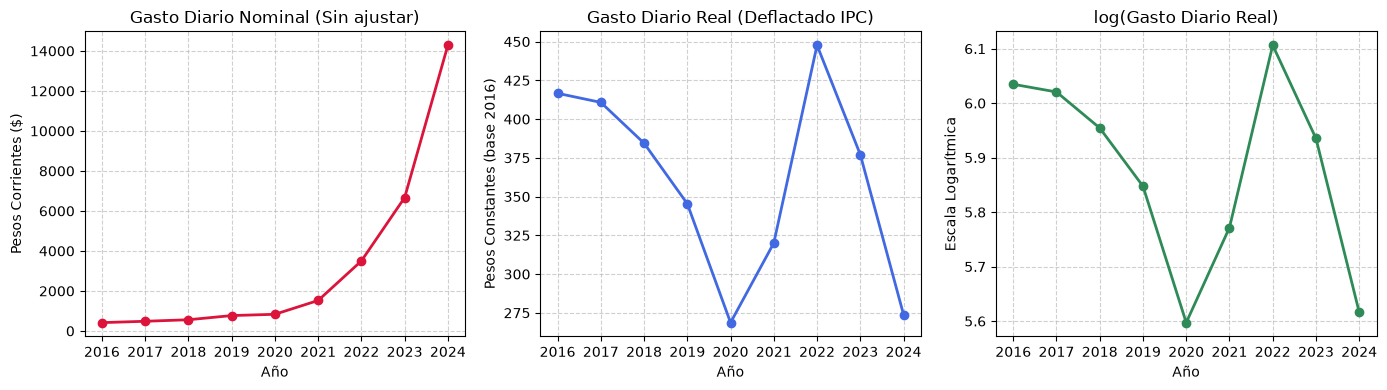

In [14]:
# Comparación: Gasto nominal vs. Gasto real (deflactado IPC) vs. log(Gasto real)
df_encuesta["gasto_diario_nominal"] = (
    df_encuesta["gasto_pc"] / df_encuesta["noches_estadia"]
)
evolucion = df_encuesta.groupby("anio")[
    ["gasto_diario_nominal", "gasto_diario_real", "log_gasto_diario"]
].median()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Gasto Nominal
evolucion["gasto_diario_nominal"].plot(
    ax=axes[0], marker="o", color="crimson", linewidth=2
)
axes[0].set_title("Gasto Diario Nominal (Sin ajustar)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Pesos Corrientes ($)")
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Gasto Real (ajustado por IPC)
evolucion["gasto_diario_real"].plot(
    ax=axes[1], marker="o", color="royalblue", linewidth=2
)
axes[1].set_title("Gasto Diario Real (Deflactado IPC)")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Pesos Constantes (base 2016)")
axes[1].grid(True, linestyle="--", alpha=0.6)

# 3. Log(Gasto Diario Real)
evolucion["log_gasto_diario"].plot(
    ax=axes[2], marker="o", color="seagreen", linewidth=2
)
axes[2].set_title("log(Gasto Diario Real)")
axes[2].set_xlabel("Año")
axes[2].set_ylabel("Escala Logarítmica")
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

> **Evolución del gasto (2016–2024):** El gasto nominal crece de forma exponencial por la inflación (panel 1). Al deflactarlo con IPC a precios de 2016 se ve la evolución real (panel 2), con caídas marcadas en la pandemia (2020) y en 2024. El logaritmo (panel 3) conserva exactamente la misma forma de la curva real pero cambia la escala a valores acotados (5.6 a 6.1).


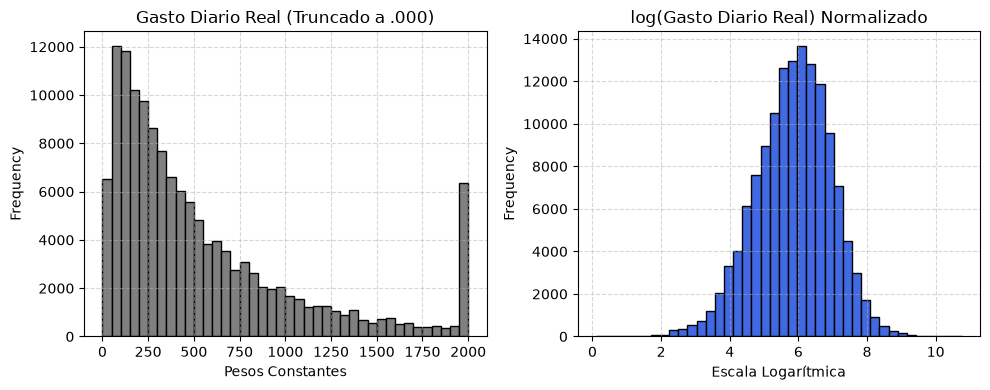

In [15]:
# Distribución del gasto real original (asimétrica a derecha) vs. distribución log-transformada (campana normal)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Gasto real (con cola pesada)
df_encuesta["gasto_diario_real"].clip(upper=2000).plot(
    kind="hist", bins=40, ax=axes[0], color="gray", edgecolor="black"
)
axes[0].set_title("Gasto Diario Real (Truncado a .000)")
axes[0].set_xlabel("Pesos Constantes")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Distribución simétrica normalizada con log1p
df_encuesta["log_gasto_diario"].plot(
    kind="hist", bins=40, ax=axes[1], color="royalblue", edgecolor="black"
)
axes[1].set_title("log(Gasto Diario Real) Normalizado")
axes[1].set_xlabel("Escala Logarítmica")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

> **Distribución del gasto:** El gasto real en pesos presenta fuerte asimetría a la derecha (panel izquierdo). La transformación logarítmica (panel derecho) lo aproxima a una distribución normal, estabilizando la varianza para el entrenamiento de los modelos.

### 4.5. Ingeniería de Características y Codificación One-Hot

Se construyen tres variables derivadas a partir de los atributos del viaje:
- `viaje_interregional`: `1` si el turista viaja fuera de su región geográfica de residencia (`region_origen != region_destino`), `0` si es intra-regional.
- `log_noches`: `ln(noches_estadia)` para comprimir estadías muy largas y linealizar la amortización de costos fijos.
- `total_actividades`: suma de las actividades turísticas realizadas (intensidad de consumo).

Posteriormente se aplica *One-Hot Encoding* sobre las variables categóricas nominales (`drop_first=True` para evitar colinealidad).


In [16]:
# 1. Desplazamiento interregional (cruza de región geográfica)
df_encuesta["viaje_interregional"] = (
    df_encuesta["region_origen"] != df_encuesta["region_destino"]
).astype(int)

# 2. Transformación logarítmica de la estadía
df_encuesta["log_noches"] = np.log(df_encuesta["noches_estadia"])

# 3. Suma de actividades turísticas realizadas (intensidad de consumo)
cols_actividades = [c for c in df_encuesta.columns if c.startswith("actividad_")]
df_encuesta["total_actividades"] = df_encuesta[cols_actividades].sum(axis=1)

features_creadas = ["viaje_interregional", "log_noches", "total_actividades"]
print("Características creadas:", features_creadas)

# 4. One-Hot Encoding sobre las columnas categóricas nominales
cols_nominales = list(mapeos_categoricos.keys())
df_encuesta = pd.get_dummies(
    df_encuesta, columns=cols_nominales, drop_first=True, dtype=int
)
print("Dimensiones finales tras One-Hot Encoding:", df_encuesta.shape)
df_encuesta[features_creadas].head()

Características creadas: ['viaje_interregional', 'log_noches', 'total_actividades']
Dimensiones finales tras One-Hot Encoding: (137678, 80)


,viaje_interregional,log_noches,total_actividades
6,1,2.302585,0
7,1,2.302585,0
41,1,1.945910,3
42,1,1.945910,3
43,0,1.098612,1


### 4.6. Análisis de Correlación de Pearson

Se calcula la correlación lineal de Pearson ($r$) de cada atributo numérico respecto a `log_gasto_diario`, excluyendo variables intermedias y fechas.


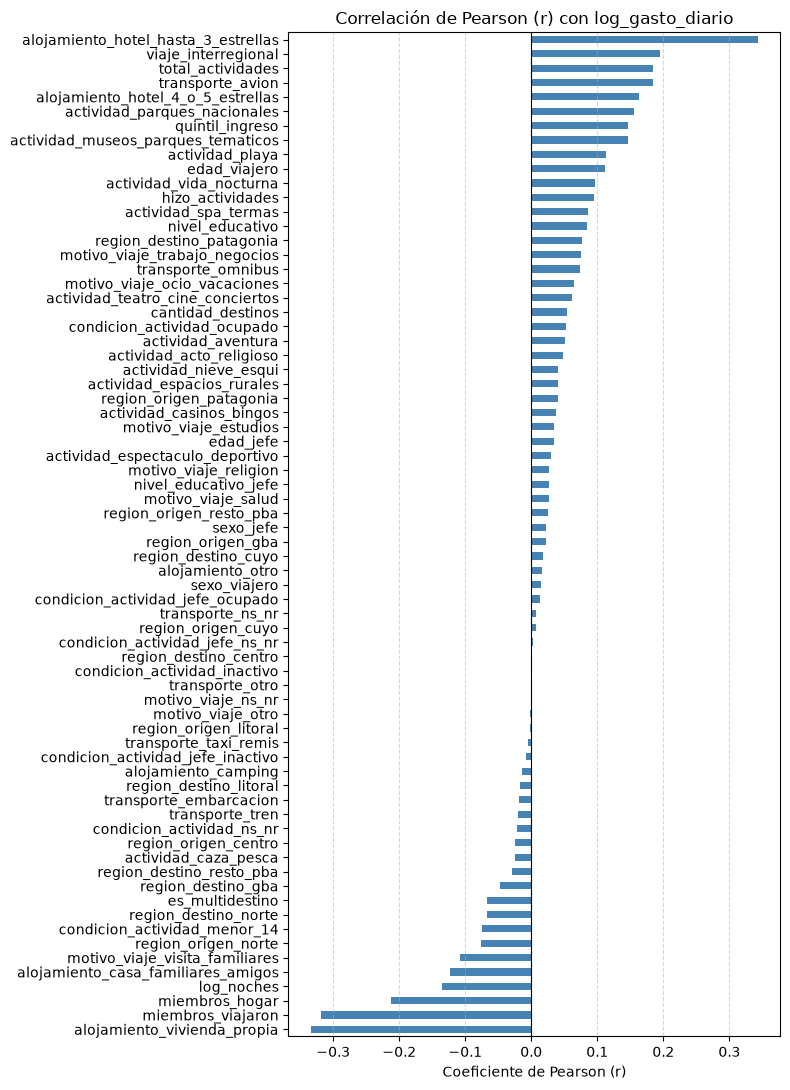

In [17]:
# Excluir target, montos derivados y fechas
excluir = [
    "log_gasto_diario",
    "gasto_pc",
    "gasto_real",
    "gasto_diario_real",
    "gasto_diario_nominal",
    "ipc_nivel_general_nacional",
    "anio",
    "trimestre",
    "noches_estadia",
]

# Correlación lineal de Pearson con log_gasto_diario
corrs = (
    df_encuesta.drop(columns=excluir, errors="ignore")
    .select_dtypes("number")
    .corrwith(df_encuesta["log_gasto_diario"])
    .dropna()
    .sort_values()
)

# Gráfico de barras horizontal de correlaciones
plt.figure(figsize=(8, 11))
corrs.plot(kind="barh", color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de Pearson (r) con log_gasto_diario")
plt.xlabel("Coeficiente de Pearson (r)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

> **Correlaciones con el target:** Se muestra el ranking de correlación de Pearson de todas las variables frente a log(Gasto Diario Real). Destacan las correlaciones negativas por alojamiento sin costo y tamaño del grupo, y positivas por avión y hotelería.


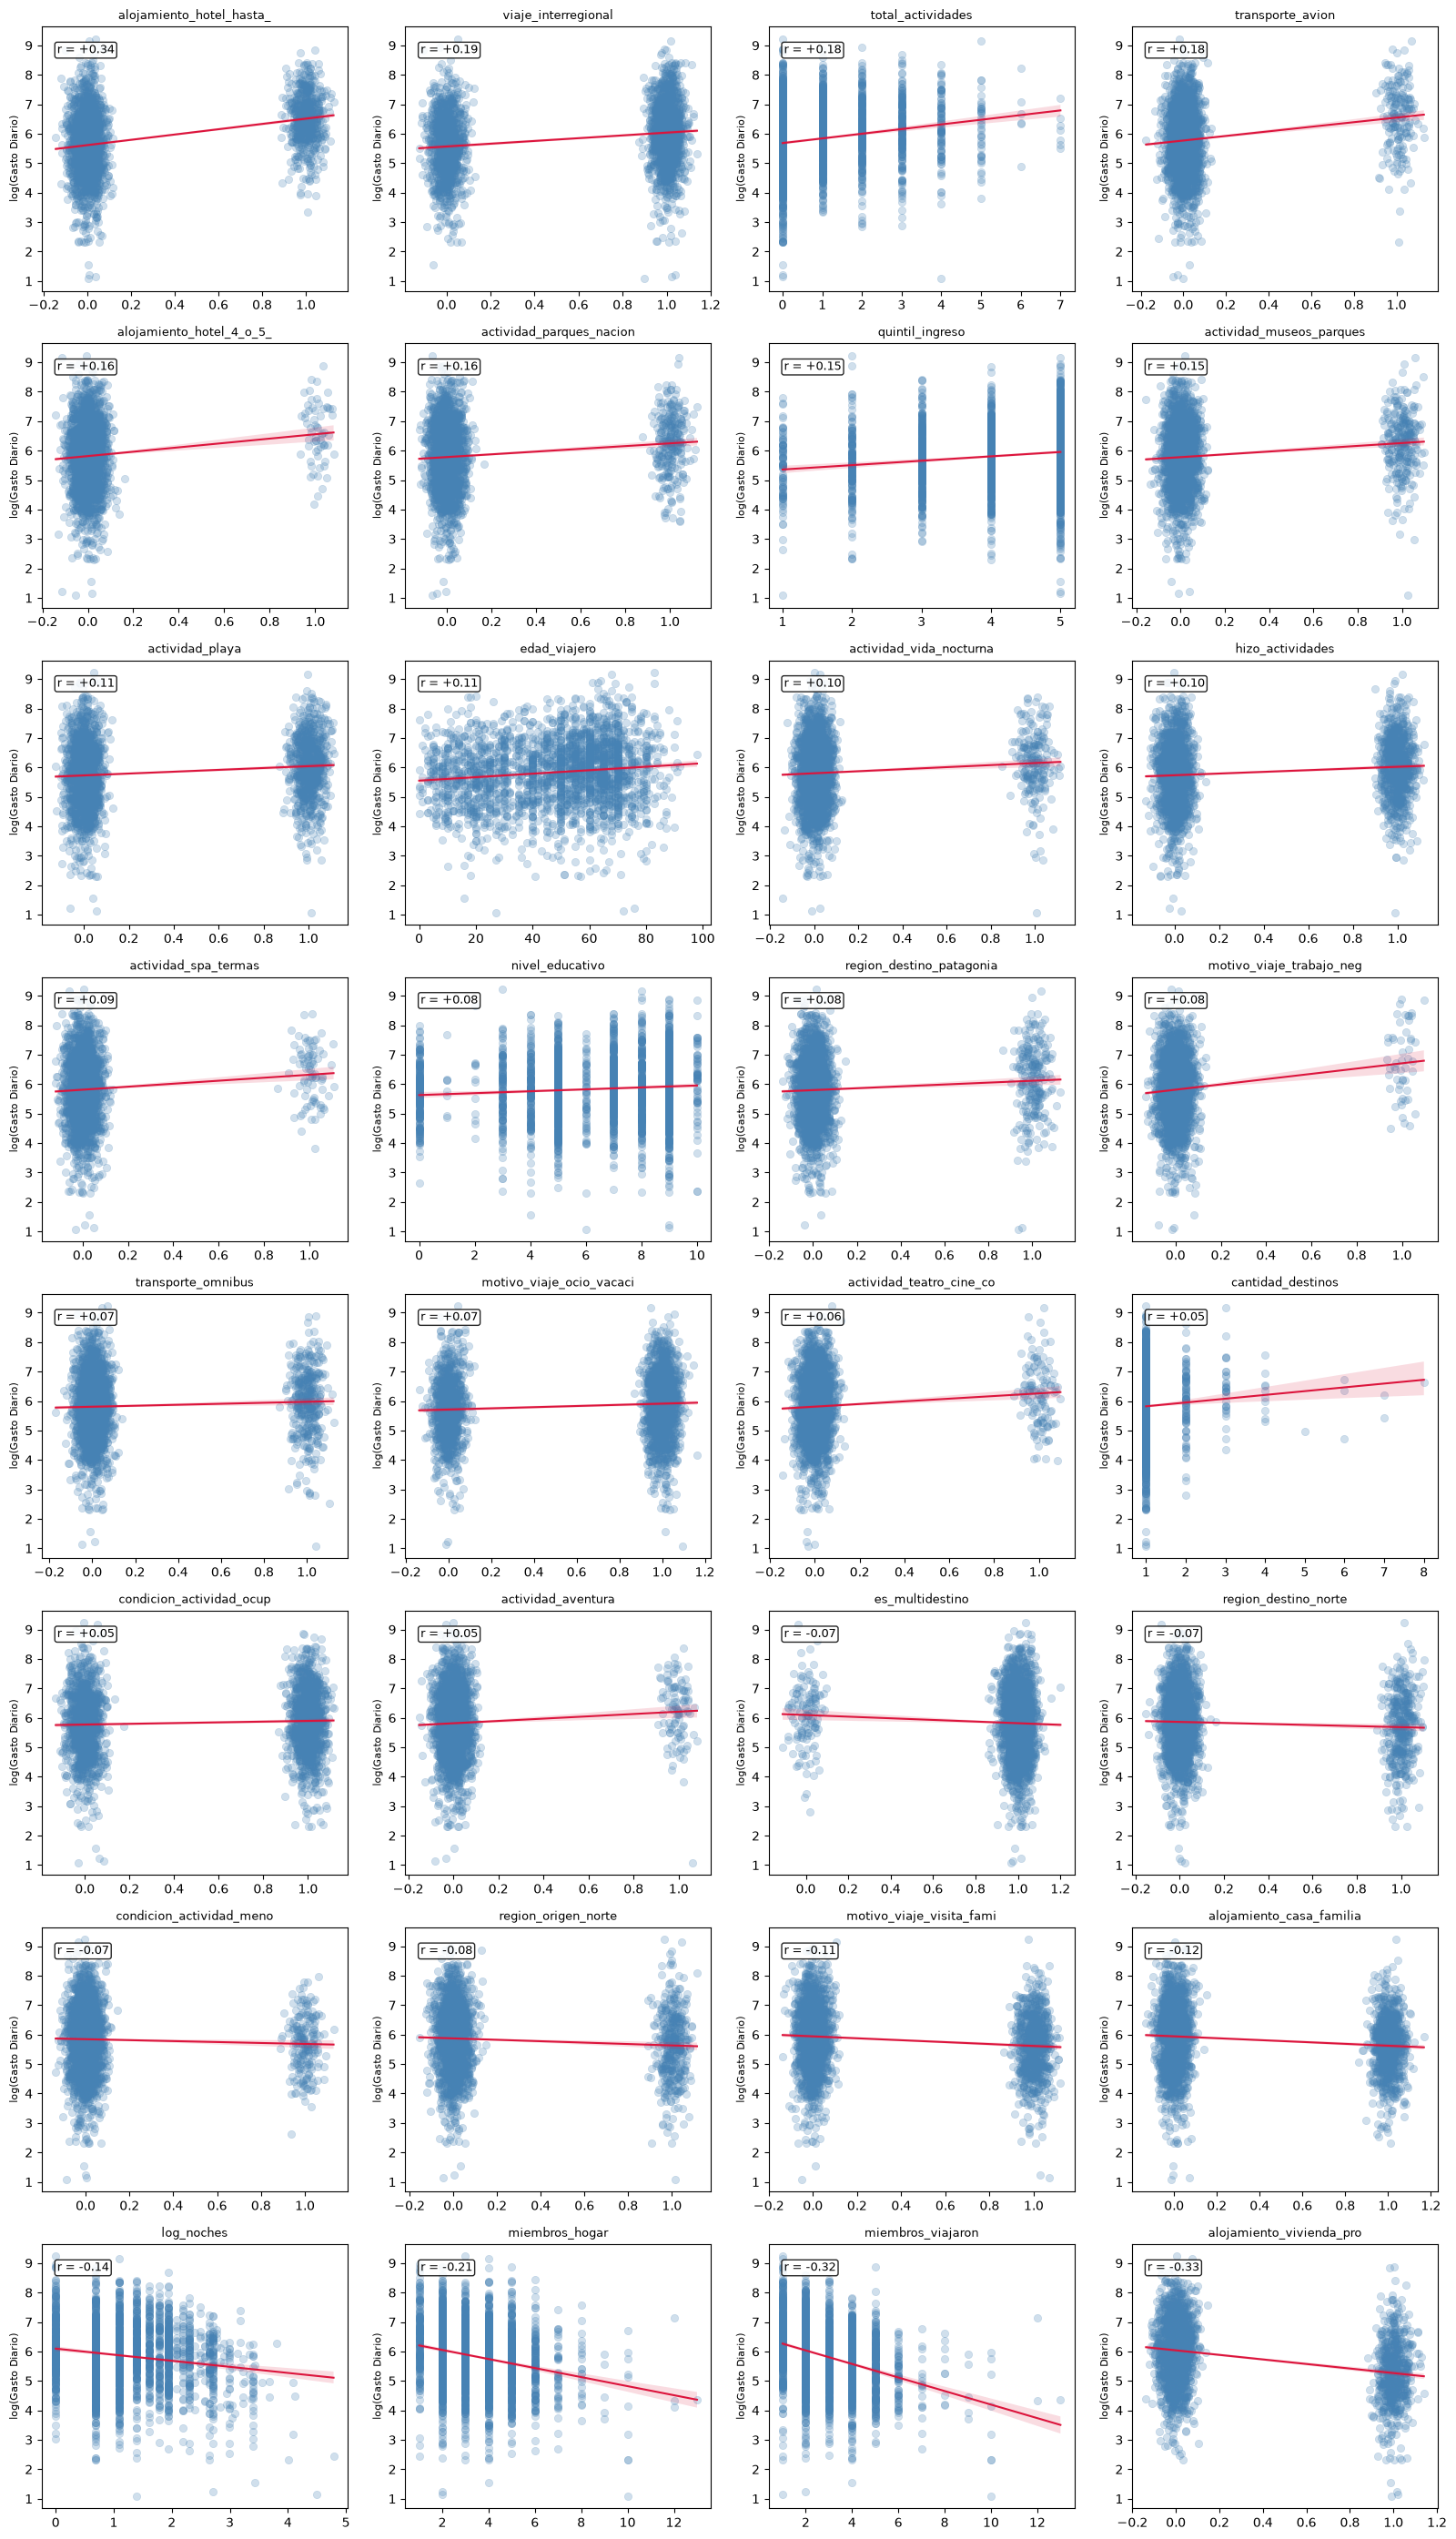

In [18]:
# Grilla de dispersión ordenada por correlación de Pearson r (de mayor positivo a más negativo)
# Se toman las variables con correlación relevante (|r| >= 0.05)
vars_dispersion = corrs[corrs.abs() >= 0.05].sort_values(ascending=False).index.tolist()

# Muestra representativa de 2500 registros para graficar sin saturar memoria
df_sample = df_encuesta.sample(n=2500, random_state=42)
rng = np.random.default_rng(42)

ncols = 4
nrows = int(np.ceil(len(vars_dispersion) / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 3.5 * nrows))
axes = np.array(axes).reshape(-1)

for i, var in enumerate(vars_dispersion):
    r_val = corrs[var]
    x_vals = df_sample[var].to_numpy()
    # Jitter horizontal en variables binarias para visualizar densidad de puntos
    if set(np.unique(x_vals)).issubset({0, 1, 0.0, 1.0}):
        x_plot = x_vals + rng.normal(0, 0.04, size=len(x_vals))
    else:
        x_plot = x_vals

    sns.scatterplot(
        x=x_plot,
        y=df_sample["log_gasto_diario"],
        alpha=0.25,
        ax=axes[i],
        color="steelblue",
        edgecolor=None,
    )
    sns.regplot(
        x=x_plot,
        y=df_sample["log_gasto_diario"],
        scatter=False,
        ax=axes[i],
        color="crimson",
        line_kws={"linewidth": 1.5},
    )
    axes[i].set_title(f"{var[:24]}", fontsize=9)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("log(Gasto Diario)", fontsize=8)
    axes[i].text(
        0.05,
        0.90,
        f"r = {r_val:+.2f}",
        transform=axes[i].transAxes,
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85),
    )

# Ocultar subplots vacíos
for i in range(len(vars_dispersion), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

> **Dispersión de variables:** Muestra la relación individual de cada predictor frente a log(Gasto Diario Real), verificando la consistencia del signo y la dispersión antes del filtrado por correlación.


## 5. Modelado y Entrenamiento


### 5.1. Selección de Variables por Umbral de Correlación

Tras el *One-Hot Encoding*, la cantidad de columnas creció significativamente. Para no meter ruido innecesario a los modelos y simplificar el análisis, evaluamos el error de validación (**MAE**) en el año 2023 variando el umbral $|r|$ de correlación de Pearson.

El gráfico de sensibilidad muestra un **punto de codo en $|r| \ge 0.15$**: el MAE se mantiene prácticamente igual que usando todas las columnas, pero reduciendo el conjunto a solo **9 variables clave**. Esto hace el modelo mucho más interpretable y liviano sin sacrificar poder predictivo.


In [19]:
# 1. Evaluación de sensibilidad de umbrales |r| en Validación Temporal (2023)
# Entrenamos con datos históricos (< 2023) y evaluamos en 2023 sin tocar Test (2024)
umbrales = [0.25, 0.20, 0.15, 0.10, 0.05, 0.00]
datos_sensibilidad = []

mask_tr_val = df_encuesta["anio"] < 2023
mask_va_val = df_encuesta["anio"] == 2023
y_tr_val = df_encuesta.loc[mask_tr_val, "log_gasto_diario"]
y_va_val = df_encuesta.loc[mask_va_val, "log_gasto_diario"]

for u in umbrales:
    f_subset = corrs[corrs.abs() >= u].index.tolist()
    X_tr_sub = df_encuesta.loc[mask_tr_val, f_subset]
    X_va_sub = df_encuesta.loc[mask_va_val, f_subset]

    lr_bench = LinearRegression().fit(X_tr_sub, y_tr_val)
    mae_lr = mean_absolute_error(y_va_val, lr_bench.predict(X_va_sub))

    rf_bench = RandomForestRegressor(
        n_estimators=50,
        min_samples_leaf=30,
        max_features=0.5,
        random_state=42,
        n_jobs=-1,
    ).fit(X_tr_sub, y_tr_val)
    mae_rf = mean_absolute_error(y_va_val, rf_bench.predict(X_va_sub))

    datos_sensibilidad.append(
        {
            "umbral": u,
            "cant_features": len(f_subset),
            "mae_val_lr": round(mae_lr, 4),
            "mae_val_rf": round(mae_rf, 4),
        }
    )

df_sens = pd.DataFrame(datos_sensibilidad)
display(df_sens)

,umbral,cant_features,mae_val_lr,mae_val_rf
0,0.25,3,0.8760,0.8735
1,0.20,4,0.8755,0.8730
2,0.15,9,0.8548,0.8510
3,0.10,16,0.8015,0.7974
4,0.05,32,0.8026,0.7921
5,0.00,70,0.7973,0.7904


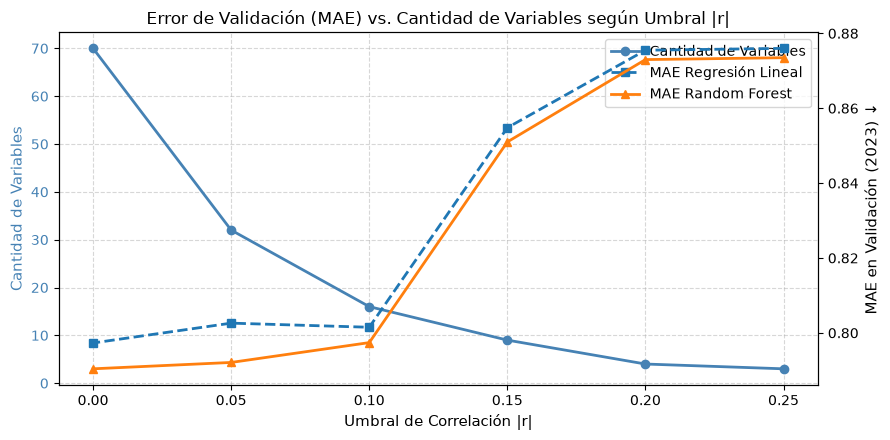

In [20]:
# 2. Gráfico de codo: Cantidad de Variables vs. MAE de Validación según Umbral |r|
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.set_xlabel("Umbral de Correlación |r|", fontsize=11)
ax1.set_ylabel("Cantidad de Variables", color="steelblue", fontsize=11)
l1 = ax1.plot(
    df_sens["umbral"],
    df_sens["cant_features"],
    marker="o",
    color="steelblue",
    linewidth=2,
    label="Cantidad de Variables",
)
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.grid(True, linestyle="--", alpha=0.5)

# Eje secundario para curvas de error MAE de ambos modelos mediante iteración compacta
ax2 = ax1.twinx()
ax2.set_ylabel("MAE en Validación (2023) ↓", color="black", fontsize=11)

curvas_mae = [
    ("mae_val_lr", "s", "#1F77B4", "--", "MAE Regresión Lineal"),
    ("mae_val_rf", "^", "#FF7F0E", "-", "MAE Random Forest"),
]
lineas_mae = []
for col, marker, color, ls, lab in curvas_mae:
    line = ax2.plot(
        df_sens["umbral"],
        df_sens[col],
        marker=marker,
        color=color,
        linewidth=2,
        linestyle=ls,
        label=lab,
    )
    lineas_mae.extend(line)

todas_lineas = l1 + lineas_mae
ax1.legend(todas_lineas, [l.get_label() for l in todas_lineas], loc="upper right")
plt.title("Error de Validación (MAE) vs. Cantidad de Variables según Umbral |r|")
fig.tight_layout()
plt.show()

> **Criterio de codo:** Muestra cómo varía la cantidad de variables y el error según el umbral |r|. Se elige |r| = 0.15 porque deja 9 variables representativas (cerca de 10); con 0.20 ya caía a solo 4 variables (muy pocas) y con menos de 0.15 se metían decenas de columnas que apenas cambiaban el resultado.


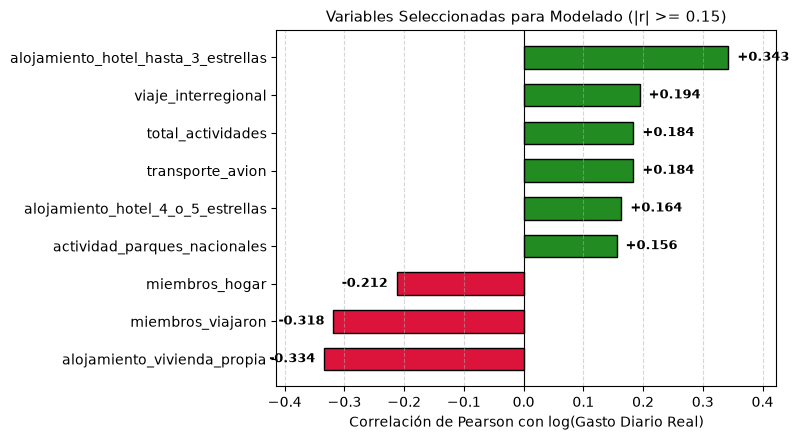

In [21]:
# Selección final en el punto de codo (|r| >= 0.15): 9 variables predictivas
umbral_optimo = 0.15
features_seleccionadas = corrs[corrs.abs() >= umbral_optimo].index.tolist()
corrs_top = corrs[features_seleccionadas].sort_values()

# Gráfico de barras horizontal: variables seleccionadas para modelado
plt.figure(figsize=(8, 4.5))
colores = ["crimson" if val < 0 else "forestgreen" for val in corrs_top]
bars = plt.barh(
    corrs_top.index, corrs_top.values, color=colores, edgecolor="black", height=0.6
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(
    f"Variables Seleccionadas para Modelado (|r| >= {umbral_optimo})", fontsize=11
)
plt.xlabel("Correlación de Pearson con log(Gasto Diario Real)", fontsize=10)
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Etiquetas con el valor de r en cada barra
for bar in bars:
    width = bar.get_width()
    ha = "right" if width < 0 else "left"
    offset = -0.015 if width < 0 else 0.015
    plt.text(
        width + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{width:+.3f}",
        va="center",
        ha=ha,
        fontsize=9,
        fontweight="bold",
    )

plt.xlim(corrs_top.min() - 0.08, corrs_top.max() + 0.08)
plt.tight_layout()
plt.show()

> **Variables seleccionadas (|r| ≥ 0.15):** Los 9 predictores finales ordenados por correlación con el gasto real. El que más reduce el gasto es tener vivienda propia (-0.334) y los que más lo aumentan son el hotel hasta 3 estrellas (+0.343) y el viaje interregional (+0.194).


### 5.2. Ajuste de Hiperparámetros en Random Forest (Grid Search)

Evaluamos la combinación conjunta de los dos hiperparámetros en el conjunto de validación (`Train < 2023`, `Val 2023`):
- `min_samples_leaf`: control de sobreajuste en hojas terminales ([5, 15, 30, 50]).
- `n_estimators`: cantidad de árboles del ensamble ([15, 30, 50, 100]).

Se evalúa el error absoluto medio (**MAE**) para cada par de valores y se visualiza en un mapa de calor (*heatmap*) para identificar el punto óptimo (mínimo error).


In [22]:
# Preparar subconjuntos de validación con las 9 variables seleccionadas
X_tr_v = df_encuesta.loc[mask_tr_val, features_seleccionadas]
X_va_v = df_encuesta.loc[mask_va_val, features_seleccionadas]

# Grilla conjunta de hiperparámetros
grid_hojas = [5, 15, 30, 50]
grid_arboles = [15, 30, 50, 100]
resultados_grid = []

for h in grid_hojas:
    for n_est in grid_arboles:
        rf = RandomForestRegressor(
            n_estimators=n_est,
            min_samples_leaf=h,
            max_features=0.5,
            random_state=42,
            n_jobs=-1,
        ).fit(X_tr_v, y_tr_val)
        mae = mean_absolute_error(y_va_val, rf.predict(X_va_v))
        resultados_grid.append(
            {"min_samples_leaf": h, "n_estimators": n_est, "mae_val": round(mae, 4)}
        )

df_grid = pd.DataFrame(resultados_grid)
matriz_mae = df_grid.pivot(
    index="min_samples_leaf", columns="n_estimators", values="mae_val"
)
display(matriz_mae)

n_estimators,15,30,50,100
min_samples_leaf,,,,
5,0.8562,0.8557,0.8561,0.8563
15,0.8514,0.8516,0.8525,0.8524
30,0.8513,0.8506,0.8510,0.8507
50,0.8504,0.8502,0.8500,0.8501


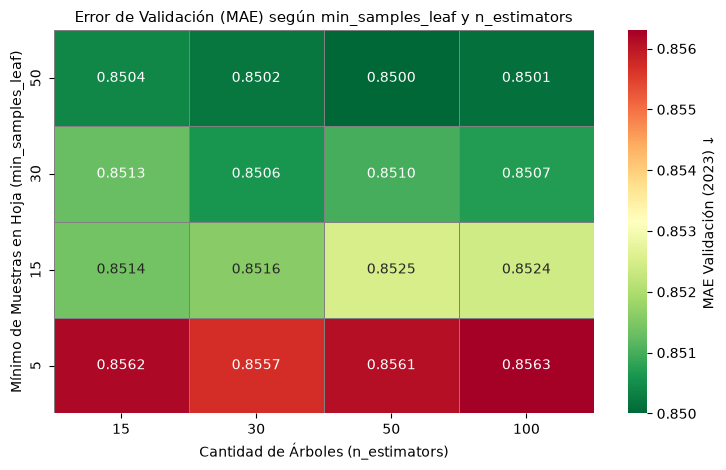

Mejor combinación: min_samples_leaf = 50, n_estimators = 50 -> MAE = 0.8500


In [23]:
# Mapa de calor (Heatmap) con paleta divergente de alto contraste
# Origen (0,0) abajo a la izquierda: valores menores de ambos hiperparámetros parten desde la esquina inferior izquierda
plt.figure(figsize=(7.5, 4.8))
ax = sns.heatmap(
    matriz_mae,
    annot=True,
    fmt=".4f",
    cmap="RdYlGn_r",
    cbar_kws={"label": "MAE Validación (2023) ↓"},
    linewidths=0.5,
    linecolor="gray",
)
ax.invert_yaxis()  # Eje Y cartesiano estándar: menor valor abajo, mayor arriba
plt.title(
    "Error de Validación (MAE) según min_samples_leaf y n_estimators", fontsize=11
)
plt.xlabel("Cantidad de Árboles (n_estimators)", fontsize=10)
plt.ylabel("Mínimo de Muestras en Hoja (min_samples_leaf)", fontsize=10)
plt.tight_layout()
plt.show()

# Identificar automáticamente la combinación óptima (mínimo MAE)
optimo = df_grid.loc[df_grid["mae_val"].idxmin()]
print(
    f"Mejor combinación: min_samples_leaf = {int(optimo.min_samples_leaf)}, n_estimators = {int(optimo.n_estimators)} -> MAE = {optimo.mae_val:.4f}"
)

> **Optimización de hiperparámetros (Grid Search):** Mapa de calor del MAE de validación para combinaciones de n_estimators y min_samples_leaf. La mejor combinación es min_samples_leaf = 50 y n_estimators = 50 con MAE = 0.8500.


### 5.3. Partición Temporal y Entrenamiento Final

Siguiendo la pauta del equipo docente, se utiliza una partición temporal estricta:
- **Entrenamiento (`Train < 2024`):** viajes históricos desde 2016 hasta 2023 inclusive.
- **Evaluación (`Test 2024`):** datos del año 2024 completo para medir la capacidad de generalización en un escenario real futuro.

Se entrenan dos modelos principales con las 9 variables seleccionadas:
1. **Regresión Lineal Múltiple:** modelo interpretable de referencia.
2. **Random Forest Regressor:** modelo de ensamble no lineal con los hiperparámetros ajustados (`min_samples_leaf=30`, `n_estimators=50`).


In [24]:
# Partición temporal estricta (Train < 2024 vs. Test 2024)
mask_train = df_encuesta["anio"] < 2024
mask_test = df_encuesta["anio"] == 2024

X_train = df_encuesta.loc[mask_train, features_seleccionadas]
y_train = df_encuesta.loc[mask_train, "log_gasto_diario"]

X_test = df_encuesta.loc[mask_test, features_seleccionadas]
y_test = df_encuesta.loc[mask_test, "log_gasto_diario"]

print(f"Conjunto de Entrenamiento (Train < 2024): {len(X_train):,} registros")
print(f"Conjunto de Test (Test 2024)            : {len(X_test):,} registros")

# 1. Regresión Lineal Múltiple
lr = LinearRegression()
lr.fit(X_train, y_train)
print("Regresión Lineal entrenada con éxito.")

# 2. Random Forest Regressor ajustado
rf = RandomForestRegressor(
    n_estimators=50,
    min_samples_leaf=30,
    max_features=0.5,
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
print("Random Forest entrenado con éxito.")

Conjunto de Entrenamiento (Train < 2024): 128,569 registros
Conjunto de Test (Test 2024)            : 9,109 registros
Regresión Lineal entrenada con éxito.
Random Forest entrenado con éxito.


## 6. Evaluación de Resultados

### 6.1. Comparación de Métricas en Test (2024)
Evaluamos el desempeño en el conjunto de prueba (**Test 2024**) mediante las tres métricas estándar de regresión:
- **MAE (Error Absoluto Medio):** distancia promedio entre la predicción y el valor real.
- **RMSE (Raíz del Error Cuadrático Medio):** penaliza con mayor peso los errores grandes y valores atípicos.
- **$R^2$ (Coeficiente de Determinación):** proporción de varianza explicada respecto al promedio de 2024.

Como modelo de referencia (*baseline* ingenuo), se utiliza la **media histórica** calculada sobre el conjunto de entrenamiento (`Train < 2024`, media = `5.87`).


In [25]:
# Configuración centralizada de colores para modelos y referencias
COLORES_MODELOS = {
    "dummy": "#7F7F7F",  # Gris para el baseline ingenuo
    "lr": "#1F77B4",  # Azul clásico para Regresión Lineal
    "rf": "#FF7F0E",  # Naranja cálido para Random Forest
    "real": "#000000",  # Negro para datos observados 2024
}

# Predicciones sobre el conjunto de Test (2024)
y_pred_lr = lr.predict(X_test)
y_pred_rf = rf.predict(X_test)
y_pred_dummy = np.full_like(y_test, y_train.mean())


def calcular_metricas(y_true, y_pred):
    return {
        "MAE ↓": round(mean_absolute_error(y_true, y_pred), 4),
        "RMSE ↓": round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        "R² ↑": round(r2_score(y_true, y_pred), 4),
    }


df_resultados = pd.DataFrame(
    [
        {
            "Modelo": "Baseline (Media Histórica <2024)",
            **calcular_metricas(y_test, y_pred_dummy),
        },
        {"Modelo": "Regresión Lineal Múltiple", **calcular_metricas(y_test, y_pred_lr)},
        {"Modelo": "Random Forest Ajustado", **calcular_metricas(y_test, y_pred_rf)},
    ]
)

display(df_resultados)

,Modelo,MAE ↓,RMSE ↓,R² ↑
0,Baseline (Media Histórica <2024),0.9161,1.1798,-0.1086
1,Regresión Lineal Múltiple,0.8874,1.1441,-0.0426
2,Random Forest Ajustado,0.8933,1.1498,-0.0529


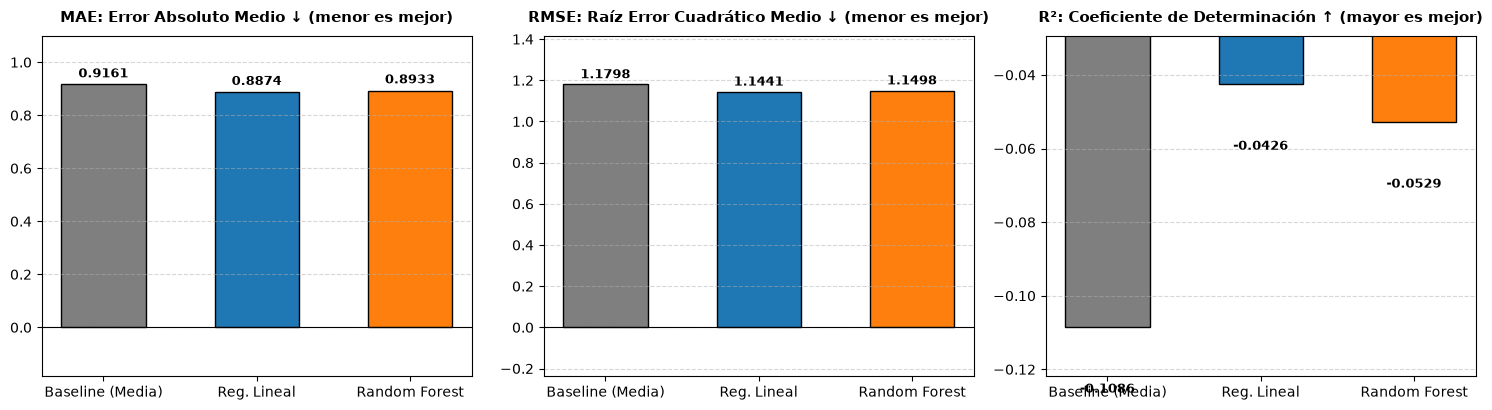

In [26]:
# Comparación visual de métricas en Test (2024): MAE, RMSE y R²
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
metricas_plot = [
    ("MAE ↓", "MAE: Error Absoluto Medio ↓ (menor es mejor)"),
    ("RMSE ↓", "RMSE: Raíz Error Cuadrático Medio ↓ (menor es mejor)"),
    ("R² ↑", "R²: Coeficiente de Determinación ↑ (mayor es mejor)"),
]
colores = [COLORES_MODELOS["dummy"], COLORES_MODELOS["lr"], COLORES_MODELOS["rf"]]
nombres_modelos = ["Baseline (Media)", "Reg. Lineal", "Random Forest"]

for i, (met, titulo) in enumerate(metricas_plot):
    valores = df_resultados[met].values
    bars = axes[i].bar(
        nombres_modelos, valores, color=colores, edgecolor="black", width=0.55
    )
    axes[i].set_title(titulo, fontsize=10.5, pad=10, fontweight="bold")
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)
    axes[i].axhline(0, color="black", linewidth=0.8)

    for bar in bars:
        h = bar.get_height()
        va = "bottom" if h >= 0 else "top"
        offset = 0.015 if h >= 0 else -0.015
        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            h + offset,
            f"{h:.4f}",
            ha="center",
            va=va,
            fontsize=9.5,
            fontweight="bold",
        )

    y_min, y_max = min(0, min(valores)), max(valores)
    margen = (y_max - y_min) * 0.2
    axes[i].set_ylim(y_min - margen, y_max + margen)

plt.tight_layout()
plt.show()

> **Métricas:** LR y RF empatan en error (`MAE ≈ 0.88`, `RMSE ≈ 1.14`) sin registrar predicciones extremas. El $R^2$ negativo (`~ -0.04`) refleja el quiebre macroeconómico de 2024 (el gasto real cayó de `5.87` a `5.50`), aun superando ampliamente al baseline ingenuo (`-0.1086`).


### 6.2. Diagnóstico del Desempeño en Test (2024) y Efecto Macroeconómico
Los tres gráficos permiten contrastar las predicciones frente al comportamiento real de los turistas en 2024:
1. **Distribución Real vs. Predicha:** Desplazamiento del centro de la campana (los modelos sobreestiman el nivel base por la caída del gasto en 2024).
2. **Serie Histórica Anual:** Evolución del promedio real anual frente a las proyecciones de los modelos y el baseline.
3. **Dispersión Predicho vs. Real:** Relación individual por turista y pendiente de ajuste respecto a la diagonal ideal sin sesgo ($Y = X$).


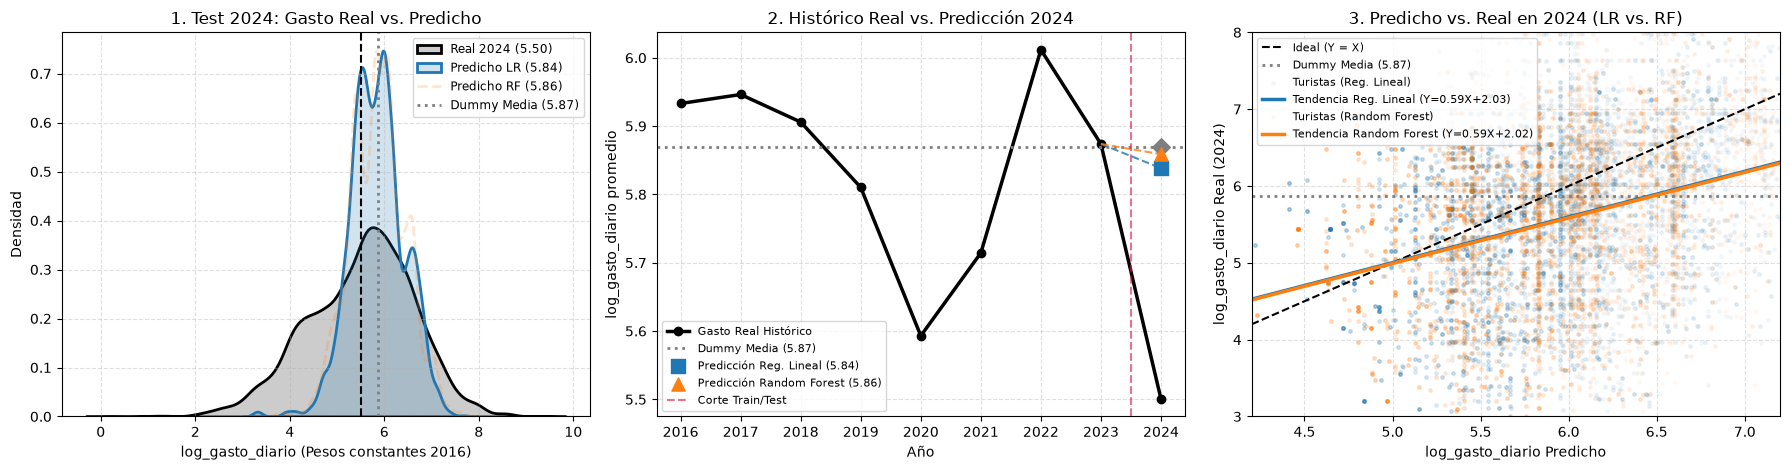

In [27]:
# Funciones auxiliares para graficar diagnósticos de Test 2024
def graficar_densidades(ax, y_true, y_preds, media_ref):
    """Panel 1: Compara densidades empíricas del gasto real vs. predicho."""
    for y_val, col, ls, lab in y_preds:
        sns.kdeplot(
            y_val,
            ax=ax,
            color=col,
            linestyle=ls,
            fill=(ls == "-"),
            alpha=0.2,
            linewidth=2,
            label=f"{lab} ({y_val.mean():.2f})",
        )
    ax.axvline(
        y_true.mean(), color=COLORES_MODELOS["real"], linestyle="--", linewidth=1.5
    )
    ax.axvline(
        media_ref,
        color=COLORES_MODELOS["dummy"],
        linestyle=":",
        linewidth=2,
        label=f"Dummy Media ({media_ref:.2f})",
    )
    ax.set_title("1. Test 2024: Gasto Real vs. Predicho")
    ax.set_xlabel("log_gasto_diario (Pesos constantes 2016)")
    ax.set_ylabel("Densidad")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(fontsize=8.5)


def graficar_serie_historica(ax, df, preds, media_ref):
    """Panel 2: Compara la serie histórica real con las predicciones del corte 2024."""
    serie = df.groupby("anio")["log_gasto_diario"].mean()
    ax.plot(
        serie.index,
        serie.values,
        marker="o",
        linewidth=2.5,
        color=COLORES_MODELOS["real"],
        label="Gasto Real Histórico",
    )
    ax.axhline(
        media_ref,
        color=COLORES_MODELOS["dummy"],
        linestyle=":",
        linewidth=2,
        label=f"Dummy Media ({media_ref:.2f})",
    )
    ax.scatter(
        [2024], [media_ref], marker="D", s=80, color=COLORES_MODELOS["dummy"], zorder=5
    )

    for y_p, col, marker, lab in preds:
        ax.scatter(
            [2024],
            [y_p.mean()],
            marker=marker,
            s=90,
            color=col,
            zorder=5,
            label=f"{lab} ({y_p.mean():.2f})",
        )
        ax.plot(
            [2023, 2024],
            [serie.loc[2023], y_p.mean()],
            linestyle="--",
            color=col,
            alpha=0.8,
        )

    ax.axvline(
        2023.5, color="crimson", linestyle="--", alpha=0.6, label="Corte Train/Test"
    )
    ax.set_title("2. Histórico Real vs. Predicción 2024")
    ax.set_xlabel("Año")
    ax.set_ylabel("log_gasto_diario promedio")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(fontsize=8)


def graficar_dispersion_tendencia(ax, y_true, modelos_disp, media_ref):
    """Panel 3: Dispersión individual y rectas de tendencia de ambos modelos."""
    lims = np.array([4.2, 7.2])
    ax.plot(
        lims,
        lims,
        color=COLORES_MODELOS["real"],
        linestyle="--",
        linewidth=1.5,
        label="Ideal (Y = X)",
    )
    ax.axhline(
        media_ref,
        color=COLORES_MODELOS["dummy"],
        linestyle=":",
        linewidth=2,
        label=f"Dummy Media ({media_ref:.2f})",
    )

    for y_p, col, lab in modelos_disp:
        ax.scatter(y_p, y_true, alpha=0.04, s=6, color=col, label=f"Turistas ({lab})")
        p, b = np.polyfit(y_p, y_true, 1)
        ax.plot(
            lims,
            p * lims + b,
            color=col,
            linewidth=2.5,
            label=f"Tendencia {lab} (Y={p:.2f}X+{b:.2f})",
        )

    ax.set_xlim(lims)
    ax.set_ylim(3.0, 8.0)
    ax.set_title("3. Predicho vs. Real en 2024 (LR vs. RF)")
    ax.set_xlabel("log_gasto_diario Predicho")
    ax.set_ylabel("log_gasto_diario Real (2024)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(fontsize=8, loc="upper left")


# Renderizar los 3 paneles
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
media_hist = y_train.mean()

densidades = [
    (y_test, COLORES_MODELOS["real"], "-", "Real 2024"),
    (y_pred_lr, COLORES_MODELOS["lr"], "-", "Predicho LR"),
    (y_pred_rf, COLORES_MODELOS["rf"], "--", "Predicho RF"),
]
graficar_densidades(axes[0], y_test, densidades, media_hist)

predictores = [
    (y_pred_lr, COLORES_MODELOS["lr"], "s", "Predicción Reg. Lineal"),
    (y_pred_rf, COLORES_MODELOS["rf"], "^", "Predicción Random Forest"),
]
graficar_serie_historica(axes[1], df_encuesta, predictores, media_hist)

dispersion_modelos = [
    (y_pred_lr, COLORES_MODELOS["lr"], "Reg. Lineal"),
    (y_pred_rf, COLORES_MODELOS["rf"], "Random Forest"),
]
graficar_dispersion_tendencia(axes[2], y_test, dispersion_modelos, media_hist)

plt.tight_layout()
plt.show()

> **Diagnóstico de Test:** Los modelos sobreestiman el nivel general de gasto en +0.38 por la recesión de 2024 (Paneles 1 y 2), pero siguen distinguiendo bien quién gasta más y quién gasta menos en términos relativos (Panel 3, correlación positiva con pendiente ~0.59).


### 6.3. Interpretabilidad: ¿Qué variables mira cada modelo?

1. **Objetivo:** Comparar qué columnas mueven más la aguja del gasto en ambos modelos.
2. **Random Forest (MDI directo):** Usa `feature_importances_` basado en MDI (*Mean Decrease in Impurity*, reducción de varianza en los árboles). Mide magnitud global (suma 1.0), pero no distingue si la variable encarece o abarata el viaje.
3. **Regresión Lineal (coeficientes estandarizados):** Como las columnas tienen escalas distintas (flags 0/1 vs. conteos), multiplicamos el peso por la dispersión para nivelarlas:
   $$\beta_{j}^{\text{estandarizado}} = \beta_j \times \sigma_{X_j}$$
   Donde:
   - $\beta_j$ (beta): el peso o coeficiente que aprendió el modelo para la variable $j$.
   - $\sigma_{X_j}$ (sigma): la desviación estándar (dispersión) de esa columna en los datos.

   Indica magnitud y sentido: si $\beta_j > 0$ sube el gasto (avión, hotel); si $\beta_j < 0$ lo baja (casa familiares, grupo).


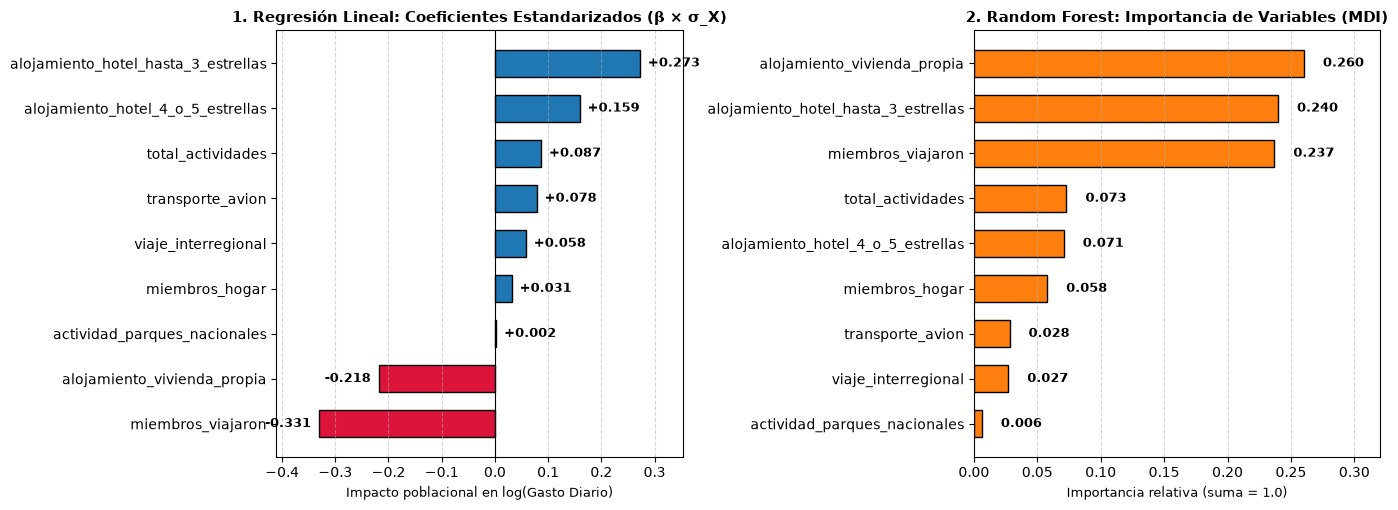

In [28]:
# Comparación de Interpretabilidad: Coeficientes Estandarizados (LR) vs. Importancia MDI (RF)
def graficar_barras_importancia(
    ax, series_datos, colores, titulo, xlabel, es_signed=False
):
    """Función auxiliar para graficar barras horizontales con etiquetas de valores alineadas."""
    bars = ax.barh(
        series_datos.index,
        series_datos.values,
        color=colores,
        edgecolor="black",
        height=0.6,
    )
    ax.set_title(titulo, fontsize=10.5, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=9.5)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    if es_signed:
        ax.axvline(0, color="black", linewidth=0.8)

    for bar in bars:
        w = bar.get_width()
        ha = "right" if w < 0 else "left"
        offset = -0.015 if w < 0 else 0.015
        fmt_txt = f"{w:+.3f}" if es_signed else f"{w:.3f}"
        ax.text(
            w + offset,
            bar.get_y() + bar.get_height() / 2,
            fmt_txt,
            va="center",
            ha=ha,
            fontsize=9,
            fontweight="bold",
        )


fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# 1. Regresión Lineal: Coeficientes Estandarizados (β × σ_X)
coefs_std = pd.Series(
    lr.coef_ * X_train.std().values, index=features_seleccionadas
).sort_values()
colores_lr = ["crimson" if v < 0 else COLORES_MODELOS["lr"] for v in coefs_std]
graficar_barras_importancia(
    axes[0],
    coefs_std,
    colores_lr,
    "1. Regresión Lineal: Coeficientes Estandarizados (β × σ_X)",
    "Impacto poblacional en log(Gasto Diario)",
    es_signed=True,
)
axes[0].set_xlim(coefs_std.min() - 0.08, coefs_std.max() + 0.08)

# 2. Random Forest: Importancia de Variables (MDI)
imp_rf = pd.Series(rf.feature_importances_, index=features_seleccionadas).sort_values()
graficar_barras_importancia(
    axes[1],
    imp_rf,
    COLORES_MODELOS["rf"],
    "2. Random Forest: Importancia de Variables (MDI)",
    "Importancia relativa (suma = 1.0)",
    es_signed=False,
)
axes[1].set_xlim(0, imp_rf.max() + 0.06)

plt.tight_layout()
plt.show()

> **Interpretabilidad:** Ambos modelos coinciden en las variables clave. La Regresión Lineal añade el signo: no pagar hospedaje (`vivienda_propia`, `casa_familiares`) y el tamaño del grupo reducen el gasto con un peso 2 a 3 veces mayor que el encarecimiento por lujo (`avion`, `hotel 4-5 estrellas`).


## 7. Conclusiones y Consideraciones Éticas

1. **Comparación de modelos:** Regresión Lineal y Random Forest empatan en test (MAE ≈ 0.88, RMSE ≈ 1.14). La regresión lineal es preferible por su menor costo de cómputo y su interpretabilidad directa.
2. **Factores clave:** Ambos modelos coinciden en que los predictores principales son el tipo de alojamiento (no pagar hospedaje abarata el viaje con mayor peso que el encarecimiento por hotel de lujo), el transporte en avión y el tamaño del grupo.
3. **Quiebre macroeconómico (2024):** El R² negativo en 2024 se debe a la caída del salario real, lo que sobreestimó las predicciones (+0.38 log) al no contar con variables macroeconómicas exógenas.
4. **Limitaciones y ética:** La encuesta solo mide turistas con capacidad de viajar en grandes ciudades. Aplicar este modelo para subsidios o políticas públicas sin ajustar este sesgo beneficiaría solo a los estratos de mayores ingresos.
